# **PROJECT PHASE II**
**Rachel MacMillan // rem388** <br>
**Valentina Fernández // jvf48**

## **Research Question:** <br>
**How do patterns of leisure activities, including television viewing, social media use, reading, and exercise, differ across age groups, and how are these differences associated with cognitive and mental health assessment outcomes?**

Research on prolonged passive media consumption (such as binge-watching or "doomscrolling") shows that these activities negatively affect cognitive function and mental-wellbeing. Alternatively, active leisure activities such as reading and exercise are frequently associated with positive cognitive and psychological outcomes. 

Determining how leisure activities affect cognitive function and mental-wellbeing typically requires controlled experimental studies, which are difficult to conduct and beyond the scope of this project. Instead, we will investigate how leisure activity patterns vary across age groups and whether those patterns are associated with differences in cognitive and mental health assessments. 

By combining datasets that measure leisure activities, demographic characteristics, and cognitive or mental health outcomes, we hope to identify meaningful relationships between lifestyle behaviors and well-being. In particular, we are interested in whether age groups characterized by greater participation in passive screen-based activities differ from groups that spend more time reading or exercising with respect to measures such as distractibility, forgetfulness, and overall mental health. While our analysis will not establish causation, it may reveal patterns that help motivate future research on how different forms of leisure activity relate to cognitive and psychological well-being during diffrent stages of life.

## **Datasets and Descriptions:**

**[2025 American Time Use Survey: Activity Summary File](https://www.bls.gov/tus/data/datafiles-2025.htm):** <br>
The U.S. Census Bureau annually conducts the American Time Use Survey (ATUS), funded by the U.S Bereau of Labor Statistics, which measures how American's divide their time among daily activities. These activities are organized into major categories such as personal care, eating and drinking, household activities, work, education, leisure and sports, and communication, with each category further divided into more detailed subcategories. 

ATUS participants are randomly selected from a subset of households that have completed their eighth month of interviews for the U.S. Census Population Survey. Participants are then interviewed once to collect time-use data of their previous day. Demographic information such as age, sex, martial status, occupation, income, and education are also recorded for each participant. Survey respondants understand that no identifiable information will be shared and that their contributing time-use data can be used for public analysis. 

ATUS provides several microdatasets regarding information on the respondant, activity, and activity summary. We will use ATUS's [Activity Summary File](https://drive.google.com/drive/folders/1Etczii3Ya7hL1ITElyc8QnaYF7_iJU_3?usp=sharing) (the raw data), which includes demographical and time-use data for each of the 6,145 participants. Detailed descriptions of dataset variables are included in the data cleaning section below.


**[Cognitive Assessment Questionnaire Dataset](https://data.mendeley.com/datasets/m2b8563ks5/1):** <br>
The Cognitive Assessment Questionnaire was designed to collect information about the frequency of everyday cognitive failures related to memory, perception, and attention. This survey was conducted by Vijayalaxmi Deshmukh, published by the Mendeley Data repository, and does not include any information about possible funding. 

A total of 1,399 participants completed a 25-question online survey in which they reported how often they experienced specific cognitive lapses during the previous six months. Responses were recorded on a 5-point scale ranging from 0 (Never) to 4 (Very Often). 

The questionnaire items are grouped into three dimensions of cognitive failure: Distractibility, Forgetfulness, and False Triggering. The dataset includes both the original survey responses and a processed version that classifies participants' levels of cognitive failure within each dimension as Low, Medium, or High. Detailed descriptions of dataset variables are included in the data cleaning section below.

**[2025 Behavioral Risk Factor Surveillance System Survey Data](https://www.cdc.gov/brfss/annual_data/annual_2025.html):** <br>
The U.S. Center for Disease Control and Prevention funds and annually conducts the Behavior Risk Factor Surveillance System (BRFSS) Survey, which interviews Americans on their health behaviors including if they exercise and how frequently they have bad mental health days. The purpose of the BRFSS is to help local governements monitor health disparities and address emerging public health situations. 

The total sample for the 2025 BRFSS is 356,158. We are interested in respondant's age, sleep duration, and frequency of bad mental health days. Detailed descriptions of dataset variables and data processing methods are included in the data cleaning section below. 

**[2022 Health and Retirement Study (HRS): Core Data, Version 2.0](https://hrs.isr.umich.edu/data-products):** <br>
The University of Michigan conducts the Health and Retirement Study (HRS), a longitudinal survey of approximately 20,000 people in the United States. Participants' health, cognition, employment, finances, family structure, and lifestyle are evaluated through multiple methods. The HRS began in 1992 and has continued across multiple survey waves, with its most recent wave conducted in 2024.

For this project, we use the 2022 Core HRS data (version 2.0), which contains 15,787 respondent records. We selected this wave because it is the most recent wave that has been fully released and processed, and it includes complete codebooks. Specifically, we use four respondent-level files:

- Leave-Behind Questionnaire (h22lb_r.csv & H22LB_R.txt): contains information about participants' leisure activities, including reading, educational or training activities, television viewing, computer use, exercise, and walking.
- Cognition (h22d_r.csv & H22D_R.txt): contains measures of cognitive performance, including immediate and delayed word-recall tasks, which we use as measures of memory.
- Physical Health (h22c_r.csv & H22C_R.txt): contains measures of sleep quality and daily sedentary behavior.
- Demographics (h22a_r.csv & H22A_R.txt): provides participant characteristics, such as age, that may be used for comparisons with other datasets.


## **Data Cleaning:**

In [1]:
!pip install pandas numpy duckdb 
!pip install matplotlib

In [2]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt

### **Cleaning American Time Use Dataset**

In [3]:
atus_summ = pd.read_csv("data/atusSummary/atussum_2025.dat")
atus_summ.head()

,TUCASEID,TUFINLWGT,TRYHHCHILD,TEAGE,TESEX,PEEDUCA,PTDTRACE,PEHSPNON,GTMETSTA,TELFS,...,t181401,t181501,t181599,t181601,t181801,t189999,t500101,t500103,t500105,t500106
0,20250101250011,3.193152e+07,-1,55,1,39,1,2,2,1,...,0,0,0,0,0,0,0,0,0,0
1,20250101250092,3.583641e+07,-1,58,2,41,1,2,1,5,...,0,0,0,0,0,0,0,0,0,0
2,20250101250283,2.607856e+07,-1,24,1,39,1,2,1,1,...,0,0,0,0,0,0,0,0,0,15
3,20250101250305,3.535833e+07,-1,25,2,44,7,1,1,1,...,0,0,0,0,0,0,0,0,0,0
4,20250101250594,5.520668e+06,-1,80,2,39,1,2,1,5,...,0,0,0,0,0,0,0,0,0,0


We used ATUS's [User Guide](https://www.bls.gov/tus/atususersguide.pdf) to determine which leisure activity each lexicode variable represented. 

**relevant atus_summ variables:** 
- `TUCASEID`: unique identifier for each participant
- `TEAGE`: age of participant
- `t010101`: minutes spent sleeping per day
- `t120303`: minutes spent watching TV per day
- `t120307`: minutes spent playing games (such as board games, videogames, or mobile games) per day
- `t120308`: minutes spent using computer for leisure (such as websurfing or using social media; **excludes gaming**) per day
- `t120309`: minutes spent doing arts and crafts as a hobby per day
- `t120312`: minutes spent reading for personal interest per day
- `t120313`: minutes spent writing for personal interest per day
- `t130101`: minutes spent exercising (working out or playing sports) per day

We will now create a new dataframe `activities` which includes the relevant variables and we will rename them appropriately. 

In [4]:
#activites shows the age of each participant and the minutes they spent on each activity per day
activities = pd.DataFrame({"id" : atus_summ["TUCASEID"],
                           "age" : atus_summ["TEAGE"],
                           "sleeping" : atus_summ["t010101"],
                           "watchingTV" : atus_summ["t120303"],
                           "gaming" : atus_summ["t120307"],
                           "onComputer" : atus_summ["t120308"],
                           "artsCrafts" : atus_summ["t120309"],
                           "reading" : atus_summ["t120312"],
                           "writing" : atus_summ["t120313"],
                           "exercising" : atus_summ["t130101"]})

#Ensuring that the data are integers
print("activites Data Types:")
print(activities.dtypes)
print("activites: the average minutes each participant spent on each activity per day")
activities.head(10)

activites Data Types:
id            int64
age           int64
sleeping      int64
watchingTV    int64
gaming        int64
onComputer    int64
artsCrafts    int64
reading       int64
writing       int64
exercising    int64
dtype: object
activites: the average minutes each participant spent on each activity per day


,id,age,sleeping,watchingTV,gaming,onComputer,artsCrafts,reading,writing,exercising
0,20250101250011,55,540,30,0,0,0,0,0,0
1,20250101250092,58,725,270,0,0,0,0,0,0
2,20250101250283,24,390,83,0,0,0,0,0,0
3,20250101250305,25,580,0,0,0,0,135,0,0
4,20250101250594,80,840,290,0,0,0,0,0,0
5,20250101250600,67,660,0,0,0,0,0,0,0
6,20250101250630,62,615,180,0,0,0,0,0,0
7,20250101250640,72,690,265,0,0,0,30,0,0
8,20250101250657,78,565,60,0,0,0,0,0,0
9,20250101250816,46,850,0,0,0,0,0,0,0


As a sanity check, we will compare our statistics with [ATUS's Lastest Numbers](https://www.bls.gov/tus/latest-numbers.htm), specifically ATUS reports that American's spent on average 9.03 hours sleeping in 2025. 

In [5]:
avg_hours_sleeping = (activities["sleeping"].mean())/60
print("Average Hours Sleeping in 2025: " + str(round(avg_hours_sleeping, 2)))

Average Hours Sleeping in 2025: 9.03


Now we will create `avg_activities` which will compute the average time spent on each activity for the population as a whole

In [6]:
avg_activities = duckdb.sql(""" SELECT ROUND(AVG(sleeping), 2) AS avg_sleeping, 
                                       ROUND(AVG(watchingTV), 2) AS avg_tv, 
                                       ROUND(AVG(gaming), 2) AS avg_gaming, 
                                       ROUND(AVG(onComputer), 2) AS avg_onComputer, 
                                       ROUND(AVG(artsCrafts), 2) AS avg_artsCrafts, 
                                       ROUND(AVG(reading), 2) AS avg_reading, 
                                       ROUND(AVG(writing), 2) AS avg_writing, 
                                       ROUND(AVG(exercising), 2) AS avg_exercising 
                                       FROM activities """).df()
print("Average minutes spent on each activity per day (full population):")
avg_activities.head()

Average minutes spent on each activity per day (full population):


,avg_sleeping,avg_tv,avg_gaming,avg_onComputer,avg_artsCrafts,avg_reading,avg_writing,avg_exercising
0,541.73,185.11,20.1,11.37,2.7,20.98,0.35,0.12


Next, we will create `grouped_activities` which is `activities` grouped by the following age categories:
- 15 - 24
- 25 - 34
- 35 - 44
- 45 - 54
- 55 - 64
- 65+

In [7]:
#avg_grouped_activies shows the average minutes spent doing each activity per day for each age group
avg_grouped_activities = duckdb.sql(""" SELECT age_group,
                                               COUNT(*) AS num_participants,
                                               ROUND(AVG(sleeping), 2) AS avg_sleeping,
                                               ROUND(AVG(watchingTV), 2) AS avg_tv,
                                               ROUND(AVG(gaming), 2) AS avg_gaming,
                                               ROUND(AVG(onComputer), 2) AS avg_computer,
                                               ROUND(AVG(artsCrafts), 2) AS avg_artsCrafts,
                                               ROUND(AVG(reading), 2) AS avg_reading,
                                               ROUND(AVG(writing), 2) AS avg_writing,
                                               ROUND(AVG(exercising), 2) AS avg_exercising
                                    FROM (
                                        SELECT
                                            CASE
                                                WHEN age BETWEEN 15 AND 24 THEN '15-24'
                                                WHEN age BETWEEN 25 AND 44 THEN '25-44'
                                                WHEN age BETWEEN 45 AND 64 THEN '45-64'
                                                ELSE '65+'
                                            END AS age_group,
                                            sleeping,
                                            watchingTV,
                                            gaming,
                                            onComputer,
                                            artsCrafts,
                                            reading,
                                            writing,
                                            exercising
                                        FROM activities
                                    )
                                    GROUP BY age_group
                                    ORDER BY age_group """).df()

print("avg_grouped_activities: the average minutes spent on each activity per day for each age group")
avg_grouped_activities.head()

avg_grouped_activities: the average minutes spent on each activity per day for each age group


,age_group,num_participants,avg_sleeping,avg_tv,avg_gaming,avg_computer,avg_artsCrafts,avg_reading,avg_writing,avg_exercising
0,15-24,440,610.01,115.74,54.35,19.20,3.72,10.71,0.30,0.14
1,25-44,1749,541.45,119.64,25.13,10.41,1.45,12.75,0.17,0.12
2,45-64,1827,531.52,175.18,10.71,10.08,1.95,15.44,0.36,0.12
3,65+,2130,536.60,261.70,16.94,11.64,4.16,34.61,0.50,0.12


We are also curious about the age distribution in this sample. We will create `age_distribution_activities` to illustrate the distribution. 

In [8]:
age_distribution_activities = duckdb.sql(""" SELECT age_group, 
                                            num_participants,
                                            ROUND((num_participants * 100.0 / SUM(num_participants) OVER()), 2) AS percentage_of_population
                                     FROM avg_grouped_activities
                                     GROUP BY age_group, num_participants
                                     ORDER BY age_group """).df()
age_distribution_activities.head()

,age_group,num_participants,percentage_of_population
0,15-24,440,7.16
1,25-44,1749,28.46
2,45-64,1827,29.73
3,65+,2130,34.66


### **Cleaning Cognitive Assessment Questionnaire Dataset**

First we will create `questionnaire`, which will consist of participant information and responses to the cognitive questionnaire.

In [9]:
questionnaire = pd.read_csv("data/cognitiveAssessment/Cognitive_Assessment_Anonymized_Responses.csv")
print("questionnaire: the responses from the cognitive assessment questionnaire")
questionnaire.head()

questionnaire: the responses from the cognitive assessment questionnaire


,Participant_ID,Occupation,Age,Gender,Education,Marks_10th,Marks_12th,Q1,Q2,Q3,...,Q16,Q17,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25
0,P0001,Student,27,Female,M. Tech,73.2,53.34,2,4,4,...,2,4,0,1.0,4,3,4,3,0,1
1,P0002,Business,31,Male,B Tech (agri),0.6,0.55,1,0,2,...,1,1,0,0.0,1,0,1,0,0,1
2,P0003,Business,36,Male,MBA,60,62,3,0,0,...,1,2,0,1.0,2,1,2,0,1,1
3,P0004,Student,23,Male,Bsc,85,75,0,0,0,...,0,0,0,0.0,0,0,0,0,0,1
4,P0005,other add this feature,29,Female,M pharm,75 %,0.61,1,1,0,...,0,0,1,1.0,1,1,1,0,1,1


Then we will create `processed_data` which includes evalutations for the forgetfulness, distractibility, and `False Triggering categories.

In [10]:
processed_data = pd.read_csv("data/cognitiveAssessment/Cognitive_Assessment_Processed_Data.csv")
print("processed_data: the processed data from the cognitive assessment")
processed_data.head()

processed_data: the processed data from the cognitive assessment


,Participant_ID,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,...,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Forgetfulness_Category,Distractibility_Category,False_Triggering_Category
0,P0001,2,4,4,4,3,4,1,0,2,...,1.0,4,3,4,3,0,1,Mild,High,No
1,P0002,1,0,2,1,2,1,0,1,1,...,0.0,1,0,1,0,0,1,Mild,Low,Yes
2,P0003,3,0,0,0,1,0,2,2,2,...,1.0,2,1,2,0,1,1,Mild,High,Yes
3,P0004,0,0,0,0,0,0,0,1,0,...,0.0,0,0,0,0,0,1,Mild,High,No
4,P0005,1,1,0,0,0,1,0,0,0,...,1.0,1,1,1,0,1,1,Mild,Low,Yes


We are interested in each participant's age and their measures of forgetfulness, distractibility, and false triggering. So we will create `cognitive_data`, which will combine the relevant variables in the `questionnaire` and `processed_data` datasets.

In [11]:
cognitive_data = duckdb.sql(""" SELECT questionnaire.Participant_ID AS id,
                                       questionnaire.Age AS age,
                                       processed_data.Forgetfulness_Category AS forgetfulness,
                                       processed_data.Distractibility_Category AS distractibility,
                                       processed_data.False_Triggering_Category AS false_triggering
                                FROM questionnaire 
                                INNER JOIN processed_data 
                                ON questionnaire.Participant_ID = processed_data.Participant_ID """).df()
cognitive_data.head()

,id,age,forgetfulness,distractibility,false_triggering
0,P0001,27,Mild,High,No
1,P0002,31,Mild,Low,Yes
2,P0003,36,Mild,High,Yes
3,P0004,23,Mild,High,No
4,P0005,29,Mild,Low,Yes


We then will ensure that our data is of the correct type.

In [12]:
print("Original data types of cognitive_data:")
print(cognitive_data.dtypes)

#convert age to int by extracting the numeric part of the string and converting it to int
#source for extracting number from string: https://www.geeksforgeeks.org/pandas/python-pandas-series-str-extract/#google_vignette
cognitive_data["age"] = cognitive_data["age"].str.extract(r"(\d+)").astype(int)

print()
print("Data types after converting age to int:")
print(cognitive_data.dtypes)

Original data types of cognitive_data:
id                  str
age                 str
forgetfulness       str
distractibility     str
false_triggering    str
dtype: object

Data types after converting age to int:
id                    str
age                 int64
forgetfulness         str
distractibility       str
false_triggering      str
dtype: object


Because we cannot easily get the average of the categorical data, we group `cognitive_data` by the same age group as we did with `avg_grouped_activities` and aggregate by the counts of each measure for each category.

In [43]:
#ChatGPT was used to generate this SQL query
grouped_cognitive_data = duckdb.sql(""" SELECT age_group, 
                                               COUNT(*) AS num_participants,
                                               ROUND(100.0 * COUNT(CASE WHEN forgetfulness = 'Mild' THEN 1 END) / COUNT(*), 2) AS low_forgetfulness_percentage,
                                               ROUND(100.0 * COUNT(CASE WHEN forgetfulness = 'Moderate' THEN 1 END) / COUNT(*), 2) AS medium_forgetfulness_percentage,
                                               ROUND(100.0 * COUNT(CASE WHEN forgetfulness = 'High' THEN 1 END) / COUNT(*), 2) AS high_forgetfulness_percentage,
                                              
                                               ROUND(100.0 * COUNT(CASE WHEN distractibility = 'Low' THEN 1 END) / COUNT(*), 2) AS low_distractibility_percentage,
                                               ROUND(100.0 * COUNT(CASE WHEN distractibility = 'Medium' THEN 1 END) / COUNT(*), 2) AS medium_distractibility_percentage,
                                               ROUND(100.0 * COUNT(CASE WHEN distractibility = 'High' THEN 1 END) / COUNT(*), 2) AS high_distractibility_percentage,
                                              
                                               ROUND(100.0 * COUNT(CASE WHEN false_triggering = 'Yes' THEN 1 END) / COUNT(*), 2) AS yes_false_triggering_percentage,
                                               ROUND(100.0 * COUNT(CASE WHEN false_triggering = 'None' THEN 1 END) / COUNT(*), 2) AS no_false_triggering_percentage
                                       FROM (
                                            SELECT
                                                CASE
                                                    WHEN age BETWEEN 15 AND 24 THEN '15-24'
                                                    WHEN age BETWEEN 25 AND 44 THEN '25-44'
                                                    WHEN age BETWEEN 45 AND 64 THEN '45-64'
                                                    ELSE '65+'
                                                END AS age_group,
                                            forgetfulness,
                                            distractibility,
                                            false_triggering
                                        FROM cognitive_data
                                            )
                                    GROUP BY age_group
                                    ORDER BY age_group """).df()
grouped_cognitive_data.head()

,age_group,num_participants,low_forgetfulness_percentage,medium_forgetfulness_percentage,high_forgetfulness_percentage,low_distractibility_percentage,medium_distractibility_percentage,high_distractibility_percentage,yes_false_triggering_percentage,no_false_triggering_percentage
0,15-24,388,88.92,7.73,3.35,32.99,31.44,35.57,52.58,0.0
1,25-44,960,90.63,6.67,2.71,35.21,33.23,31.56,49.27,0.0
2,45-64,50,86.00,12.00,2.00,34.00,30.00,36.00,50.00,0.0
3,65+,1,100.00,0.00,0.00,0.00,100.00,0.00,100.00,0.0


We will create `age_distribution_cognitive_data` to illustrate the age distribution of the sample. 

In [14]:
age_distribution_cognitive_data = duckdb.sql(""" SELECT age_group, 
                                                num_participants,
                                                ROUND((num_participants * 100.0 / SUM(num_participants) OVER()), 2) AS percentage_of_population
                                         FROM grouped_cognitive_data
                                         GROUP BY age_group, num_participants
                                         ORDER BY age_group """).df()
age_distribution_cognitive_data.head()

,age_group,num_participants,percentage_of_population
0,15-24,388,27.73
1,25-44,960,68.62
2,45-64,50,3.57
3,65+,1,0.07


### **Cleaning BRFSS Dataset** 

BRFSS's 2025 [raw data file](https://drive.google.com/drive/folders/1sUQI14nSPj7OGtmp5o7pN4t1tV5-zlNq) includes 356,158 participants with over 200 variables, so we loaded it into jupyter lab and used BRFSS's [Calculated Variables Document](https://www.cdc.gov/brfss/annual_data/2025/pdf/2025-calculated-variables-version4-508.pdf) to determine 4 relevant variables. 

**Variables** <br>
- `SEQNO`: participant's unique ID
- `_AGE80`: participant's age
- `_TOTINDA`: integer that track's participant's physical activity: <br>
                - (1) participant exercised within the last 30 days <br>
                - (2) participant has not exercised within the last 30 days <br>
                - (9) participant doesn't know/refuses to answer/missing data <br>
- `_MENT14D`: integer that track's participant's bad mental health days within the past 30 days: <br>
                - (1) participant had no bad mental health days <br>
                - (2) participant had 1-13 bad mental health days <br>
                - (3) participant had 14+ bad mental health days <br>
                - (9) participant doesn't know/refuses to answer/missing data <br>

In [15]:
mental_health = pd.read_csv("data/BRFSS/mental_health.csv")
mental_health.head()

#check data types
print("Original data types of mental_health:")
print(mental_health.dtypes)
print()

#convert _AGE80, _TOTINDA, and _MENT14D to int
mental_health["_AGE80"] = mental_health["_AGE80"].astype(int)
mental_health["_TOTINDA"] = mental_health["_TOTINDA"].astype(int)
mental_health["_MENT14D"] = mental_health["_MENT14D"].astype(int)

print("Current data types of mental_health:")
print(mental_health.dtypes)
print()

Original data types of mental_health:
SEQNO           str
_AGE80      float64
_TOTINDA    float64
_MENT14D    float64
dtype: object

Current data types of mental_health:
SEQNO         str
_AGE80      int64
_TOTINDA    int64
_MENT14D    int64
dtype: object



Now we will rename the variables for clearity.

In [16]:
mental_health.rename(columns = {"_AGE80": "age", 
                                "_TOTINDA": "exercise", 
                                "_MENT14D": "bad_mental_health_days",
                                "SEQNO": "id"}, inplace = True)

mental_health.head()

,id,age,exercise,bad_mental_health_days
0,b'2025000001',71,1,2
1,b'2025000002',80,1,1
2,b'2025000003',68,2,1
3,b'2025000004',80,2,1
4,b'2025000005',64,1,2


Some summary statistics on the whole population:

In [17]:
print("Average Age: " + str(round(mental_health["age"].mean(), 2)))
print("Standard Deviation of Age: " + str(round(mental_health["age"].std(), 2)))
print("Minimum Age: " + str(mental_health["age"].min()))
print("Maximum Age: " + str(mental_health["age"].max()))

Average Age: 55.77
Standard Deviation of Age: 18.36
Minimum Age: 18
Maximum Age: 80


Now we will create `grouped_mental_health`, grouping `mental_health` by the same age groups as before. 

In [44]:
#ChatGPT was used to generate this SQL query
grouped_mental_health = duckdb.sql(""" SELECT age_group,
                                              COUNT(*) AS num_participants,
                                              ROUND(100.0 * COUNT(CASE WHEN exercise = '1' THEN 1 END) / COUNT(*), 2) AS exercised_percentage,
                                              ROUND(100.0 * COUNT(CASE WHEN exercise = '2' THEN 1 END) / COUNT(*), 2) AS not_exercised_percentage,
                                              ROUND(100.0 * COUNT(CASE WHEN exercise = '9' THEN 1 END) / COUNT(*), 2) AS missing_exercise_percentage,
                                              
                                              ROUND(100.0 * COUNT(CASE WHEN bad_mental_health_days = '1' THEN 1 END) / COUNT(*), 2) AS no_bad_mental_health_days_percentage,
                                              ROUND(100.0 * COUNT(CASE WHEN bad_mental_health_days = '2' THEN 1 END) / COUNT(*), 2) AS half_bad_mental_health_days_percentage,
                                              ROUND(100.0 * COUNT(CASE WHEN bad_mental_health_days = '3' THEN 1 END) / COUNT(*), 2) AS most_bad_menal_health_days_percentage,
                                              ROUND(100.0 * COUNT(CASE WHEN bad_mental_health_days = '9' THEN 1 END) / COUNT(*), 2) AS missing_bad_mental_health_days_percentage,
                                    FROM (
                                        SELECT
                                            CASE
                                                WHEN age BETWEEN 15 AND 24 THEN '15-24'
                                                WHEN age BETWEEN 25 AND 44 THEN '25-44'
                                                WHEN age BETWEEN 45 AND 64 THEN '45-64'
                                                ELSE '65+'
                                            END AS age_group,
                                                   exercise,
                                                   bad_mental_health_days,
                                        FROM mental_health
                                    )
                                    GROUP BY age_group
                                    ORDER BY age_group """).df()

print("grouped_mental_health: mental_health data grouped by age group")
grouped_mental_health.head()

grouped_mental_health: mental_health data grouped by age group


,age_group,num_participants,exercised_percentage,not_exercised_percentage,missing_exercise_percentage,no_bad_mental_health_days_percentage,half_bad_mental_health_days_percentage,most_bad_menal_health_days_percentage,missing_bad_mental_health_days_percentage
0,15-24,23238,85.20,14.58,0.22,38.80,39.77,19.79,1.64
1,25-44,82299,82.26,17.59,0.15,43.64,35.55,19.30,1.51
2,45-64,108396,76.49,23.25,0.26,56.54,25.94,15.89,1.64
3,65+,142225,72.06,27.57,0.37,71.61,17.43,8.80,2.17


As with our other datasets, we will create `age_distribution_mental_health` to consider how prevalent each group in within this survey.

In [19]:
age_distribution_mental_health = duckdb.sql(""" SELECT age_group, 
                                                num_participants,
                                                ROUND((num_participants * 100.0 / SUM(num_participants) OVER()), 2) AS percentage_of_population
                                         FROM grouped_mental_health
                                         GROUP BY age_group, num_participants
                                         ORDER BY age_group """).df()
age_distribution_mental_health.head()

,age_group,num_participants,percentage_of_population
0,15-24,23238,6.52
1,25-44,82299,23.11
2,45-64,108396,30.43
3,65+,142225,39.93


Now we will create `age_distribution` which will combine the `age_distribution_activities`, `age_distribution_cognitive_data`, and `age_distribution_mental_health` datasets. This combined dataset allows us to compare the age distributions of our study samples and assess how representative they are of the broader population.

In [20]:
#age_distribution: shows age distribution across all three datasets
age_distribution = pd.concat([age_distribution_activities,
                              age_distribution_cognitive_data,
                              age_distribution_mental_health],
                              ignore_index=True)
age_distribution = age_distribution.groupby("age_group", as_index=False)["num_participants"].sum()
total = age_distribution["num_participants"].sum()
age_distribution["percentage_of_population"] = age_distribution["num_participants"] / total * 100
print("age_distribution: shows age distribution across all three datasets")
age_distribution

age_distribution: shows age distribution across all three datasets


,age_group,num_participants,percentage_of_population
0,15-24,24066,6.616937
1,25-44,85008,23.372917
2,45-64,110273,30.319519
3,65+,144356,39.690627


### **Cleaning 2022 Health and Retirement Study (HRS)**

We used the HRS 2022 [Data Description and Usage](https://hrsdata.isr.umich.edu/sites/default/files/documentation/data-descriptions/1763070409/h22dd.pdf), [Assessment Protocol](https://hrsdata.isr.umich.edu/sites/default/files/documentation/data-descriptions/1789588799/hc22_dd_RM.pdf?_gl=1*1kj3od7*_ga*MzA5OTgyNjgzLjE3OTE5MzU5MTg.*_ga_FF28MW3MW2*czE3OTI1MTE4OTkkbzYkZzEkdDE3OTI1MTE5NDEkajE4JGwwJGgw), and  the corresponding [Variable Codebooks](https://hrs.isr.umich.edu/sites/default/files/meta/2022/core/codebook/h22_00.html) to identify which files and variables are relevant to our research question. 
The HRS Core [raw dataset](https://drive.google.com/drive/folders/1w-X6-1hFte52DfkcEUk0B5e1JOHmpZVX?usp=drive_link) is organized into separate files by questionnaire section. For this project, we selected variables from four respondent-level files: <br> 
- Leave-Behind Questionnaire (`h22lb_r.csv`)
- Cognition (`h22d_r.csv`)
- Physical Health (`h22c_r.csv`)
- Coverscreen (Demographics) (`h22a_r.csv`)

**Participant Identifiers** <br>
When importing the datasets, we stored both identifiers as strings to preserve leading zeros, as recommended by the HRS documentation. Together, these identifiers allow us to match respondents across questionnaire sections.
- `HHID`: Household identification number.
- `PN`: Respondent person identification number within the household.

The HRS data measures the **frequency of participation** in different leisure activities using an ordinal scale: <br>
- `1`: Respondant participated in activity **daily**
- `2`: Respondant participated in activity **several times a week**
- `3`: Respondant participated in activity **once a week**
- `4`: Respondant participated in activity **several times a month**
- `5`: Respondant participated in activity **at least once a month**
- `6`: Respondant **has not participated** in activity **within the past month**
- `7`: Respondant **never participated** in the activity
- `(blank)`: represents participants with inappliciable status or missing information


**Leave-Behind Questionnaire (`h22lb_r.csv`)** <br>
This is a self-administered survey that collects information about respondents' psychosocial characteristics and lifestyle activities. Although it was introduced in 2004, the HRS incorporated it into the Enhanced Face-to-Face interview design in 2006. Under this design, approximately half of households were randomly selected for the enhanced interview in 2006, while the other half were selected in 2008. This alternating selection process continues across survey waves.

Because the questionnaire is administered to a selected subset of respondents rather than the entire HRS sample, we expect substantial missingness in the leisure activity variables. However, not all selected respondents necessarily complete the questionnaire, and additional eligibility requirements may affect participation. We will investigate these sources of missingness before deciding how to clean the data. <br>

**Relevant Variables:** <br>
- `SLB001E`: Frequency of attending an educational or training course
- `SLB001I`: Frequency of reading (such as books, magazines, or newspapers)
- `SLB001J`: Frequency of watching television
- `SLB001K`: Frequency of playing word games (such as crossword puzzles or Scrabble)
- `SLB001L`: Frequency of playing cards or games (such as chess)
- `SLB001M`: Frequency of writing (such as letters, stories, or journal entries)
- `SLB001N`: Frequency of using a computer for email, Internet, or other tasks.
- `SLB001R`: Frequency of working on a hobby or personal project.
- `SLB001S`: Frequency of playing sports or exercising.
- `SLB001T`: Frequency of walking for 20 minutes or more.


**Cognition (`h22d_r.csv`)** <br>
Participants are tested on their immediate and delayed memory recall through an interviewer-administered task where a total of 10 words are shown on their screen, with each word appearing for 2 seconds. The respondant is then asked to recall each word after it's been shown. `SD174` and `SD184` show the number of correct words recalled with a score ranging from 1 to 10 (1 corresponding to 1 correct word, to 10 corresponding to all 10 words recalled correctly). Higher scores indicated better performance for each corresponding memory task. <br>
- `SD174`: Number of words correctly recalled during the interviewer-administered immediate word-recall task
- `SD184`: Number of words correctly recalled during the interviewer-administered delayed word-recall task 


**Physical Health (`h22c_r.csv`)** <br>
For `SC083`,`SC084`, `SC085`, `SC086` **sleep variables**, **frequency** is measured by an ordinal scale: <br>
- `-8` : Web non-response
- `1` : Most of the time
- `2` : Sometimes
- `3` : Rarely or never
- `8` : Doesn't know
- `9` : Refused to answer
- `(blank)` : Inapplicable

**Revelant Variables:** <br>
- `SC083`: Frequency of having trouble falling asleep.
- `SC084`: Frequency of waking during the night.
- `SC085`: Frequency of waking too early and being unable to fall asleep again.
- `SC086`: Frequency of feeling rested when waking in the morning.

- `SC303`: Minutes component of self-reported daily sitting time.
    - `-8` :  Web non-response
    - `0 - 60` : Actual value
    - `98` : Don't Know/Not Ascertained
    - `99` : Refused
    - `(blank)` : Inapplicable 
- `SC304`: Hours component of self-reported daily sitting time.
    - `-8` :  Web non-response
    - `0 - 24` : Actual value
    - `98` : Don't Know/Not Ascertained
    - `99` : Refused
    - `(blank)` : Inapplicable 

The sitting-time variables `SC303` and `SC304` record the hours and minutes respondents usually spend sitting during a typical day, excluding sleep. These components may be combined into total daily sitting time after missing and invalid responses are addressed.

**Coverscreen / Demographics (`h22a_r.csv`)**
- `SA019`: Respondent's current age

Age will be used to examine how leisure activities, cognitive performance, and physical health vary across different age groups.

First, we will load in the the relevant datasets.

In [21]:
hrs_leisure_raw = pd.read_csv("data/hrs_data/2022/h22lb_r.csv", dtype = {"HHID": str, "PN": str})
hrs_cognition_raw = pd.read_csv("data/hrs_data/2022/h22d_r.csv", dtype = {"HHID": str, "PN": str})
hrs_health_raw = pd.read_csv("data/hrs_data/2022/h22c_r.csv",dtype = {"HHID": str, "PN": str})
hrs_demographics_raw = pd.read_csv("data/hrs_data/2022/h22a_r.csv",dtype={"HHID": str, "PN": str})

print()
print("hrs_leaisure_raw:")
display(duckdb.sql("SELECT * FROM hrs_leisure_raw LIMIT 5").df())
print()

print("hrs_cognition_raw:")
display(duckdb.sql("SELECT * FROM hrs_cognition_raw LIMIT 5").df())
print()

print("hrs_health_raw:")
display(duckdb.sql("SELECT * FROM hrs_health_raw LIMIT 5").df())
print()

print("hrs_demographics_raw:")
display(duckdb.sql("SELECT * FROM hrs_demographics_raw LIMIT 5").df())
print()


hrs_leaisure_raw:


,HHID,PN,SSUBHH,RSUBHH,SPN_SP,SCSR,SFAMR,SFINR,SLBRTYPE,SLBELIG,...,SLB057O,SLB057P,SLB057Q,SLB057R,SLB057S,SLB057T,SLB057U,SLB059,SVDATE,SVERSION
0,010001,010,0,0.0,NaN,1,1,1,1,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,2
1,010003,030,0,0.0,NaN,1,1,1,4,1,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1,2
2,010004,040,1,1.0,NaN,1,1,1,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,2
3,010013,040,1,1.0,NaN,1,1,1,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2
4,010038,010,0,0.0,40.0,1,5,1,4,1,...,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,2



hrs_cognition_raw:


,HHID,PN,SSUBHH,RSUBHH,SPN_SP,SCSR,SFAMR,SFINR,SD190,SD101,...,SD552,SD553,SD554,SD555,SD556,SD557,SWEBNONRSP,SDMODE,SVDATE,SVERSION
0,010001,010,0,0.0,NaN,1,1,1,0.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,5,2
1,010003,030,0,0.0,NaN,1,1,1,0.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1,2
2,010004,040,1,1.0,NaN,1,1,1,0.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,6,2
3,010013,040,1,1.0,NaN,1,1,1,0.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,3,2
4,010038,010,0,0.0,40.0,1,5,1,0.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1,2



hrs_health_raw:


,HHID,PN,SSUBHH,RSUBHH,SPN_SP,SCSR,SFAMR,SFINR,SC231,SC234,...,SC178,SC179,SC180,SC181,SC182,SC183,SWEBNONRSP,SCMODE,SVDATE,SVERSION
0,010001,010,0,0.0,NaN,1,1,1,0,1,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,2.0,5,2
1,010003,030,0,0.0,NaN,1,1,1,0,1,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,2.0,1,2
2,010004,040,1,1.0,NaN,1,1,1,0,1,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,2.0,6,2
3,010013,040,1,1.0,NaN,1,1,1,0,1,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,3,2
4,010038,010,0,0.0,40.0,1,5,1,0,1,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,2.0,1,2



hrs_demographics_raw:


,HHID,PN,SSUBHH,RSUBHH,SPN_SP,SCSR,SFAMR,SFINR,SA500,SA501,...,SA068M,SA099,SA100,SA101,SA106,SA113,SWEBNONRSP,SAMODE,SVDATE,SVERSION
0,010001,010,0,0.0,NaN,1,1,1,7,2022,...,NaN,0,0,0,0,0,NaN,2.0,5,2
1,010003,030,0,0.0,NaN,1,1,1,3,2022,...,NaN,0,0,0,0,0,NaN,2.0,1,2
2,010004,040,1,1.0,NaN,1,1,1,6,2023,...,NaN,0,3,3,3,6,NaN,1.0,6,2
3,010013,040,1,1.0,NaN,1,1,1,6,2022,...,NaN,0,1,1,1,2,NaN,1.0,3,2
4,010038,010,0,0.0,40.0,1,5,1,3,2022,...,NaN,0,2,2,2,4,NaN,2.0,1,2


Now we will rename the variables accordingly.

In [22]:
hrs_leisure = duckdb.sql("SELECT HHID AS hhid, PN AS pn, " \
                         "SLB001E AS education_training, " \
                         "SLB001I AS reading, SLB001J AS watching_tv, " \
                         "SLB001K AS word_games, SLB001L AS card_games_chess, " \
                         "SLB001M AS writing, SLB001N AS computer_internet, " \
                         "SLB001R AS hobbies, SLB001S AS exercising, " \
                         "SLB001T AS walking " \
                         "FROM hrs_leisure_raw").df()

hrs_cognition = duckdb.sql("SELECT HHID AS hhid, PN AS pn, " \
                           "SD174 AS immediate_recall, " \
                           "SD184 AS delayed_recall " \
                           "FROM hrs_cognition_raw").df()

hrs_health = duckdb.sql("SELECT HHID AS hhid, PN AS pn, " \
                        "SC083 AS trouble_falling_asleep, " \
                        "SC084 AS waking_at_night, " \
                        "SC085 AS waking_too_early, " \
                        "SC086 AS feeling_rested, " \
                        "SC303 AS sitting_minutes, " \
                        "SC304 AS sitting_hours " \
                        "FROM hrs_health_raw").df()

hrs_demographics = duckdb.sql("SELECT HHID AS hhid, PN AS pn, " \
                              "SA019 AS age FROM hrs_demographics_raw").df()

print()
print("hrs_leisure:")
display(hrs_leisure.head())
print()

print("hrs_cognition:")
display(hrs_cognition.head())
print()

print("hrs_health:")
display(hrs_health.head())
print()

print("hrs_demographics:")
display(hrs_demographics.head())


hrs_leisure:


,hhid,pn,education_training,reading,watching_tv,word_games,card_games_chess,writing,computer_internet,hobbies,exercising,walking
0,010001,010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,010003,030,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,010004,040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,010013,040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,010038,010,7.0,1.0,1.0,7.0,7.0,7.0,1.0,1.0,1.0,1.0



hrs_cognition:


,hhid,pn,immediate_recall,delayed_recall
0,010001,010,4.0,0.0
1,010003,030,5.0,2.0
2,010004,040,7.0,5.0
3,010013,040,5.0,6.0
4,010038,010,4.0,4.0



hrs_health:


,hhid,pn,trouble_falling_asleep,waking_at_night,waking_too_early,feeling_rested,sitting_minutes,sitting_hours
0,010001,010,2.0,2.0,3.0,1.0,0.0,2.0
1,010003,030,8.0,1.0,1.0,1.0,NaN,4.0
2,010004,040,3.0,3.0,3.0,1.0,0.0,5.0
3,010013,040,3.0,3.0,3.0,1.0,NaN,4.0
4,010038,010,2.0,1.0,2.0,1.0,5.0,NaN



hrs_demographics:


,hhid,pn,age
0,010001,010,83
1,010003,030,66
2,010004,040,77
3,010013,040,74
4,010038,010,85


### Checking Variables for Missing Values

Before cleaning the HRS data, we will inspect the missing values in the Leave-Behind Questionnaire. Unlike the other HRS sections, this questionnaire is administered to a selected subset of respondents through the Enhanced Face-to-Face survey design. Additionally, for HRS leisure variables we calculate the number and percentage of missing values for each selected leisure activity variable before making any cleaning decisions.

To understand blank or `NaN` responses, we will consider: <br>
- `SLBRTYPE` : the interview type
    - `1`: Not Enhanced Face to Face R
    - `2`: Enhanced Face to Face R, phone interview
    - `3`: Enhanced Face to Face R, proxy or nursing home resident
    - `4`: Enhanced Face to Face R, self-respondent, FTF interview, not in nursing home
- `SLBCOMP` : whether responded completed the Leave-Behind Questionnaire
    - `1`: **Completed**; returned by mail
    - `2`: **Completed** by phone with interviewer
    - `3`: **Completed**Completed by other than assigned respondant
    - `4`: **Not Completed**
    - `(blank): Non eligible
- `SLBELIG`: respondant eligibility for Leave-Behind Questionnaire
    - `1`: respondant is **eligible**
    - `5`: respondant is **not eligible**

This allows us to distinguish missing responses associated with the survey design from those potentially caused by questionnaire noncompletion.

In [23]:
for col in ["SLBRTYPE", "SLBELIG", "SLBCOMP"]:
    display(hrs_leisure_raw[col].value_counts(dropna=False).sort_index())

SLBRTYPE
1    7149
2    1782
3     100
4    6756
Name: count, dtype: int64

SLBELIG
1    8638
5    7149
Name: count, dtype: int64

SLBCOMP
1.0    4442
4.0      23
5.0    4274
NaN    7048
Name: count, dtype: int64

The according to `SLBELIG`, only 8,638 participants were elegible for the leave behind questionare. We will factor this in and remove `NaN` variables, as they are blank spaces for respondents who did not receive questons. This will show the scale and actual mssing information in leave-behind questionare.

In [24]:
# Select respondents eligible for the Leave-Behind Questionnaire
eligible_ids = hrs_leisure_raw.loc[hrs_leisure_raw["SLBELIG"] == 1, ["HHID", "PN"]].rename(columns={"HHID": "hhid", "PN": "pn"})

hrs_leisure_eligible = hrs_leisure.merge(eligible_ids,
                                         on=["hhid", "pn"],
                                         how="inner",
                                         validate="one_to_one")

print("Total Respondents: " + str(len(hrs_leisure)))
print("Eligible Respondents: " + str(len(hrs_leisure_eligible)))
print("Ineligible Respondents: " + str(len(hrs_leisure) - len(hrs_leisure_eligible)))
print()

# Compare missingness before and after excluding ineligible respondents
leisure_vars = ["education_training",
                "reading",
                "watching_tv",
                "word_games",
                "card_games_chess",
                "writing",
                "computer_internet",
                "hobbies",
                "exercising",
                "walking"]

leisure_missing = pd.DataFrame({ "Missing (all respondents)": hrs_leisure[leisure_vars].isna().sum(),
                                 "Missing (eligible only)": hrs_leisure_eligible[leisure_vars].isna().sum(),
                                 "Missing % (eligible only)": (hrs_leisure_eligible[leisure_vars].isna().mean() * 100).round(2)})
print("Missing Respondents:")
display(leisure_missing)

Total Respondents: 15787
Eligible Respondents: 8638
Ineligible Respondents: 7149

Missing Respondents:


,Missing (all respondents),Missing (eligible only),Missing % (eligible only)
education_training,11399,4351,50.37
reading,11394,4346,50.31
watching_tv,11391,4343,50.28
word_games,11393,4345,50.30
card_games_chess,11396,4348,50.34
writing,11385,4337,50.21
computer_internet,11374,4326,50.08
hobbies,11416,4367,50.56
exercising,11425,4377,50.67
walking,11380,4332,50.15


Now we will combine `hrs_leisure`, `hrs_cognition`, `hrs_health`, and `hrs_demographics` into one DataFrame `hrs`.

In [25]:
#ChatGPT was used to generate the SQL query for combining our HRS DataFrames into a single DataFrame
hrs = duckdb.sql("SELECT l.*, c.* EXCLUDE (hhid, pn), h.* EXCLUDE (hhid, pn), d.* EXCLUDE (hhid, pn) FROM hrs_leisure AS l " \
                 "INNER JOIN hrs_cognition AS c USING (hhid, pn) " \
                 "INNER JOIN hrs_health AS h USING (hhid, pn) " \
                 "INNER JOIN hrs_demographics AS d USING (hhid, pn)").df()

display(hrs.head())
print("Combined dataset Shape: " + str(hrs.shape))

,hhid,pn,education_training,reading,watching_tv,word_games,card_games_chess,writing,computer_internet,hobbies,...,walking,immediate_recall,delayed_recall,trouble_falling_asleep,waking_at_night,waking_too_early,feeling_rested,sitting_minutes,sitting_hours,age
0,010001,010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,4.0,0.0,2.0,2.0,3.0,1.0,0.0,2.0,83
1,010003,030,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,5.0,2.0,8.0,1.0,1.0,1.0,NaN,4.0,66
2,010004,040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,7.0,5.0,3.0,3.0,3.0,1.0,0.0,5.0,77
3,010013,040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5.0,6.0,3.0,3.0,3.0,1.0,NaN,4.0,74
4,010038,010,7.0,1.0,1.0,7.0,7.0,7.0,1.0,1.0,...,1.0,4.0,4.0,2.0,1.0,2.0,1.0,5.0,NaN,85


Combined dataset Shape: (15787, 21)


### Overall Summary of the HRS Data

Before analyzing relationships between leisure activities and health or cognitive outcomes, we first summarize the combined HRS dataset. We calculate the number of participants and examine the frequency and percentage of responses for our main categorical variables, such as reading, television viewing, exercise, and sleep difficulties.

For each `activity_frequency` dataframe, it will have: <br>
- `activity` column: the activity
- `frequency` column: how frequently the partipant engaged in the activity <br>
    - `1`: Respondant participated in activity **daily**
    - `2`: Respondant participated in activity **several times a week**
    - `3`: Respondant participated in activity **once a week**
    - `4`: Respondant participated in activity **several times a month**
    - `5`: Respondant participated in activity **at least once a month**
    - `6`: Respondant **has not participated** in activity **within the past month**
    - `7`: Respondant **never participated** in the activity
- `percentage` column: represents the proportion of valid, nonblank responses in that category

These statistics help us understand the composition of our sample and the distribution of each variable. They also allow us to identify uncommon, missing, or unusual response values that may need to be addressed before further analysis.

In [26]:
#ChatGPT was used to generate the SQL queries for calculating num_participants
num_participants = duckdb.sql("SELECT COUNT(DISTINCT (hhid, pn)) FROM hrs").fetchone()[0]
print("Number of Participants: " + str(num_participants))

reading_frequency = duckdb.sql("SELECT reading, COUNT(*) " \
                               "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                               "AS percentage FROM hrs WHERE reading IS NOT NULL " \
                               "GROUP BY reading ORDER BY reading").df()

tv_frequency = duckdb.sql("SELECT watching_tv, COUNT(*) " \
                          "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                          "AS percentage FROM hrs WHERE watching_tv IS NOT NULL " \
                          "GROUP BY watching_tv ORDER BY watching_tv").df()

computer_frequency = duckdb.sql("SELECT computer_internet, COUNT(*) " \
                                "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                "AS percentage FROM hrs WHERE computer_internet IS NOT NULL " \
                                "GROUP BY computer_internet ORDER BY computer_internet").df()

exercise_frequency = duckdb.sql("SELECT exercising, COUNT(*) " \
                                "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                "AS percentage FROM hrs WHERE exercising IS NOT NULL " \
                                "GROUP BY exercising ORDER BY exercising").df()

word_games_frequency = duckdb.sql("SELECT word_games, COUNT(*) " \
                                  "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                  "AS percentage FROM hrs WHERE word_games IS NOT NULL " \
                                  "GROUP BY word_games ORDER BY word_games").df()

card_games_frequency = duckdb.sql("SELECT card_games_chess, COUNT(*) " \
                                  "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                  "AS percentage FROM hrs WHERE card_games_chess IS NOT NULL " \
                                  "GROUP BY card_games_chess ORDER BY card_games_chess").df()

writing_frequency = duckdb.sql("SELECT writing, COUNT(*) " \
                               "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                               "AS percentage FROM hrs WHERE writing IS NOT NULL " \
                               "GROUP BY writing ORDER BY writing").df()

hobbies_frequency = duckdb.sql("SELECT hobbies, COUNT(*) " \
                               "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                               "AS percentage FROM hrs WHERE hobbies IS NOT NULL " \
                               "GROUP BY hobbies ORDER BY hobbies").df()

walking_frequency = duckdb.sql("SELECT walking, COUNT(*) " \
                               "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                               "AS percentage FROM hrs WHERE walking IS NOT NULL " \
                               "GROUP BY walking ORDER BY walking").df()

education_frequency = duckdb.sql("SELECT education_training, COUNT(*) " \
                                 "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                 "AS percentage FROM hrs WHERE education_training IS NOT NULL " \
                                 "GROUP BY education_training ORDER BY education_training").df()

falling_asleep_frequency = duckdb.sql("SELECT trouble_falling_asleep, COUNT(*) " \
                                      "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                      "AS percentage FROM hrs WHERE trouble_falling_asleep IS NOT NULL " \
                                      "GROUP BY trouble_falling_asleep ORDER BY trouble_falling_asleep").df()

waking_night_frequency = duckdb.sql("SELECT waking_at_night, COUNT(*) " \
                                    "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                    "AS percentage FROM hrs WHERE waking_at_night IS NOT NULL " \
                                    "GROUP BY waking_at_night ORDER BY waking_at_night").df()

waking_early_frequency = duckdb.sql("SELECT waking_too_early, COUNT(*) " \
                                    "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                                    "AS percentage FROM hrs WHERE waking_too_early IS NOT NULL " \
                                    "GROUP BY waking_too_early ORDER BY waking_too_early").df()

rested_frequency = duckdb.sql("SELECT feeling_rested, COUNT(*) " \
                              "AS frequency, ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) " \
                              "AS percentage FROM hrs WHERE feeling_rested IS NOT NULL " \
                              "GROUP BY feeling_rested ORDER BY feeling_rested").df()
print("reading_frequency:")
display(reading_frequency)
print()

print("tv_frequency:")
display(tv_frequency)
print()

print("computer_frequency:")
display(computer_frequency)
print()

print("exercise_frequency:")
display(exercise_frequency)
print()

print("walking_frequency:")
display(walking_frequency)
print()

print("education_frequency:")
display(education_frequency)
print()

print("falling_asleep_frequency:")
display(falling_asleep_frequency)
print()

print("waking_night_frequency:")
display(waking_night_frequency)
print()

print("waking_early_frequency:")
display(waking_early_frequency)
print()

print("rested_frequency:")
display(rested_frequency)
print()

print("word_games_frequency:")
display(word_games_frequency)
print()

print("card_games_frequency:")
display(card_games_frequency)
print()

print("writing_frequency:")
display(writing_frequency)
print()

print("hobbies_frequency:")
display(hobbies_frequency)

Number of Participants: 15787
reading_frequency:


,reading,frequency,percentage
0,1.0,1802,41.02
1,2.0,802,18.26
2,3.0,348,7.92
3,4.0,437,9.95
4,5.0,373,8.49
5,6.0,273,6.21
6,7.0,358,8.15



tv_frequency:


,watching_tv,frequency,percentage
0,1.0,3547,80.69
1,2.0,523,11.90
2,3.0,73,1.66
3,4.0,89,2.02
4,5.0,42,0.96
5,6.0,43,0.98
6,7.0,79,1.80



computer_frequency:


...

,card_games_chess,frequency,percentage
0,1.0,292,6.65
1,2.0,320,7.29
2,3.0,221,5.03
3,4.0,295,6.72
4,5.0,421,9.59
5,6.0,1162,26.46
6,7.0,1680,38.26



writing_frequency:


,writing,frequency,percentage
0,1.0,213,4.84
1,2.0,267,6.07
2,3.0,160,3.63
3,4.0,300,6.82
4,5.0,424,9.63
5,6.0,959,21.79
6,7.0,2079,47.23



hobbies_frequency:


,hobbies,frequency,percentage
0,1.0,306,7.00
1,2.0,554,12.67
2,3.0,268,6.13
3,4.0,486,11.12
4,5.0,539,12.33
5,6.0,947,21.67
6,7.0,1271,29.08


Now we will create `age_recall_summary` which which shows the min/max/mean age and mean immediate/delayed recall.

In [27]:
age_recall_summary = duckdb.sql("SELECT ROUND(AVG(age), 2) AS mean_age, MIN(age) " \
                                "AS min_age, MAX(age) AS max_age, ROUND(AVG(immediate_recall), 2) " \
                                "AS mean_immediate_recall, ROUND(AVG(delayed_recall), 2) " \
                                "AS mean_delayed_recall FROM hrs").df()
display(age_recall_summary)

,mean_age,min_age,max_age,mean_immediate_recall,mean_delayed_recall
0,67.7,27,106,5.39,4.32


### HRS Summary by Age Group

Next, we create `grouped_hrs`, which summarizes the HRS data using the same age groups as we've used before. Keeping the age categories consistent will make comparisons between the two datasets easier, even when certain age groups have no HRS respondents.

We use the following age groups:

- 15–24 years
- 25–44 years
- 45–64 years
- 65+ years

Because HRS primarily focuses on middle-aged and older adults, the 15–24 age group is expected to contain no respondents. 

In [28]:
#ChatGPT was used to generate the SQL query for grouping HRS participants by age and summarizing their activities and cognitive scores
grouped_hrs = duckdb.sql("""
WITH age_groups AS (
    SELECT * FROM (VALUES
        (1, '15-24', 15, 24),
        (2, '25-44', 25, 44),
        (3, '45-64', 45, 64),
        (4, '65+', 65, NULL)
    ) AS t(age_order, age_group, min_age, max_age)
)

SELECT
    a.age_group,
    COUNT(h.hhid) AS num_participants,
    ROUND(AVG(h.age), 2) AS mean_age,

    ROUND(AVG(h.education_training), 2) AS avg_education_training,
    ROUND(AVG(h.reading), 2) AS avg_reading,
    ROUND(AVG(h.watching_tv), 2) AS avg_watching_tv,
    ROUND(AVG(h.word_games), 2) AS avg_word_games,
    ROUND(AVG(h.card_games_chess), 2) AS avg_card_games_chess,
    ROUND(AVG(h.writing), 2) AS avg_writing,
    ROUND(AVG(h.computer_internet), 2) AS avg_computer_internet,
    ROUND(AVG(h.hobbies), 2) AS avg_hobbies,
    ROUND(AVG(h.exercising), 2) AS avg_exercising,
    ROUND(AVG(h.walking), 2) AS avg_walking,

    ROUND(AVG(h.immediate_recall), 2) AS avg_immediate_recall,
    ROUND(AVG(h.delayed_recall), 2) AS avg_delayed_recall

FROM age_groups AS a
LEFT JOIN hrs AS h
    ON h.age >= a.min_age
    AND (a.max_age IS NULL OR h.age <= a.max_age)

GROUP BY a.age_order, a.age_group
ORDER BY a.age_order
""").df()

display(grouped_hrs)

,age_group,num_participants,mean_age,avg_education_training,avg_reading,avg_watching_tv,avg_word_games,avg_card_games_chess,avg_writing,avg_computer_internet,avg_hobbies,avg_exercising,avg_walking,avg_immediate_recall,avg_delayed_recall
0,15-24,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,25-44,131,40.27,6.05,2.86,1.73,4.24,4.86,4.27,1.91,4.91,4.09,2.82,6.05,5.13
2,45-64,6681,58.08,6.24,3.18,1.50,4.39,5.43,5.60,2.15,4.83,4.23,3.25,5.79,4.72
3,65+,8975,75.26,6.49,2.55,1.35,4.15,5.35,5.68,2.95,4.95,4.39,3.63,5.05,3.98


### Leave-Behind Data Availability by Age Group

We compare the age distribution of the full HRS sample with the subset of respondents who were eligible for the Leave-Behind Questionnaire and provided at least one valid leisure activity response `has_lb_data`. For each age group, we calculate the percentage of eligible respondents with available leisure data and compare the age distributions of the full sample and Leave-Behind subset.

In [29]:
#ChatGPT was used to generate this SQL query for summarizing HRS participants' leisure activity data by age group
lb_age_summary = duckdb.sql("""
WITH respondents AS (
    SELECT
        h.*,
        l.SLBELIG AS lb_eligibility,
        CASE WHEN
            h.education_training BETWEEN 1 AND 7 OR
            h.reading BETWEEN 1 AND 7 OR
            h.watching_tv BETWEEN 1 AND 7 OR
            h.word_games BETWEEN 1 AND 7 OR
            h.card_games_chess BETWEEN 1 AND 7 OR
            h.writing BETWEEN 1 AND 7 OR
            h.computer_internet BETWEEN 1 AND 7 OR
            h.hobbies BETWEEN 1 AND 7 OR
            h.exercising BETWEEN 1 AND 7 OR
            h.walking BETWEEN 1 AND 7
        THEN 1 ELSE 0 END AS has_lb_data
    FROM hrs AS h
    LEFT JOIN hrs_leisure_raw AS l
        ON h.hhid = l.HHID AND h.pn = l.PN
),

age_groups AS (
    SELECT * FROM (VALUES
        (1, '15-24', 15, 24),
        (2, '25-44', 25, 44),
        (3, '45-64', 45, 64),
        (4, '65+', 65, NULL)
    ) AS t(age_order, age_group, min_age, max_age)
),

age_counts AS (
    SELECT
        a.age_order,
        a.age_group,
        COUNT(h.hhid) AS full_hrs_n,
        COUNT(h.hhid) FILTER (
            WHERE h.lb_eligibility = 1
        ) AS eligible_n,
        COUNT(h.hhid) FILTER (
            WHERE h.lb_eligibility = 1
            AND h.has_lb_data = 1
        ) AS lb_data_n

    FROM age_groups AS a
    LEFT JOIN respondents AS h
        ON h.age >= a.min_age
        AND (a.max_age IS NULL OR h.age <= a.max_age)

    GROUP BY a.age_order, a.age_group
)

SELECT
    age_group,
    full_hrs_n,
    eligible_n,
    lb_data_n,

    ROUND(
        100.0 * lb_data_n / NULLIF(eligible_n, 0), 2
    ) AS pct_has_lb_data,

    ROUND(
        100.0 * full_hrs_n / NULLIF(SUM(full_hrs_n) OVER (), 0), 2
    ) AS pct_full_hrs_distribution,

    ROUND(
        100.0 * lb_data_n / NULLIF(SUM(lb_data_n) OVER (), 0), 2
    ) AS pct_lb_distribution

FROM age_counts
ORDER BY age_order
""").df()

display(lb_age_summary)

,age_group,full_hrs_n,eligible_n,lb_data_n,pct_has_lb_data,pct_full_hrs_distribution,pct_lb_distribution
0,15-24,0,0,0,NaN,0.00,0.00
1,25-44,131,82,21,25.61,0.83,0.48
2,45-64,6681,3738,1526,40.82,42.32,35.02
3,65+,8975,4818,2811,58.34,56.85,64.50


We compare the ages of all HRS participants with those who were eligible for the Leave-Behind Questionnaire and answered at least one leisure activity question. This helps us see what percentage of eligible participants provided leisure data in each age group and whether there is a specific age group that is under/over represented in the data. This is important to keep in mind when analyzing and understanding the data since variables from the Leave-Behind Questionnaire have the most missing data and we dont want to make any assumptions of even distribution. 

The table shows that respondents aged 65+ make up 64.50% of the Leave-Behind subset, compared with 56.85% of the full HRS sample, meaning older adults are more represented in the leisure data. 

### Cleaning HRS Sitting-Time Variables

The HRS records daily sitting time using separate variables for hours and minutes. We keep both variables in our dataset but remove special survey response codes before using them in calculations.

Invalid sleep inputs are recorded as following:
- `-8` : Web non-response
- `98` : Don't know / Not ascertained
- `99` : Refused <br>

These codes do not represent actual sitting time, so we replace them with `NaN` to avoid affecting our summary statistics.

After cleaning, we retain the hours and minutes as separate variables. If needed for later analysis, we can combine them into a single measure of total daily sitting time in minutes to make comparisons of sedentary behavior easier.

In [30]:
# Replace special response codes with NaN
hrs["sitting_hours"] = hrs["sitting_hours"].replace([-8, 98, 99], np.nan)
hrs["sitting_minutes"] = hrs["sitting_minutes"].replace([-8, 98, 99], np.nan)

print("Missing sitting hours:", hrs["sitting_hours"].isna().sum())
print("Missing sitting minutes:", hrs["sitting_minutes"].isna().sum())
display(hrs[["sitting_hours", "sitting_minutes"]].describe())

Missing sitting hours: 791
Missing sitting minutes: 6207


,sitting_hours,sitting_minutes
count,14996.000000,9580.000000
mean,5.663777,2.320668
std,3.753942,8.336168
min,0.000000,0.000000
25%,3.000000,0.000000
50%,5.000000,0.000000
75%,8.000000,0.000000
max,24.000000,60.000000


### Cleaning Sleep Variables

 Sleep frequency is measured by an ordinal scale: <br>
- `-8` : Web non-response
- `1` : Most of the time
- `2` : Sometimes
- `3` : Rarely or never
- `8` : Doesn't know
- `9` : Refused to answer
- `(blank)` : Inapplicable

 Because `-8`, `8`, and `9` codes do not represent actual levels of sleep difficulty or restfulness, we convert them to missing values before calculating averages or using the variables in exploratory analysis. We will now clean the sleep variables.

In [31]:
hrs["trouble_falling_asleep_clean"] = hrs["trouble_falling_asleep"].where(hrs["trouble_falling_asleep"].isin([1, 2, 3]), np.nan)
hrs["waking_at_night_clean"] = hrs["waking_at_night"].where(hrs["waking_at_night"].isin([1, 2, 3]), np.nan)
hrs["waking_too_early_clean"] = hrs["waking_too_early"].where(hrs["waking_too_early"].isin([1, 2, 3]), np.nan)
hrs["feeling_rested_clean"] = hrs["feeling_rested"].where(hrs["feeling_rested"].isin([1, 2, 3]), np.nan)

trouble_falling_asleep_clean = duckdb.sql("SELECT trouble_falling_asleep_clean, " \
                                          "COUNT(*) AS frequency " \
                                          "FROM hrs " \
                                          "GROUP BY trouble_falling_asleep_clean " \
                                          "ORDER BY trouble_falling_asleep_clean").df()

waking_at_night_clean = duckdb.sql("SELECT waking_at_night_clean, " \
                                   "COUNT(*) AS frequency " \
                                   "FROM hrs " \
                                   "GROUP BY waking_at_night_clean " \
                                   "ORDER BY waking_at_night_clean").df()

waking_too_early_clean = duckdb.sql("SELECT waking_too_early_clean, " \
                                    "COUNT(*) AS frequency " \
                                    "FROM hrs " \
                                    "GROUP BY waking_too_early_clean " \
                                    "ORDER BY waking_too_early_clean").df()

feeling_rested_clean = duckdb.sql("SELECT feeling_rested_clean, " \
                                  "COUNT(*) AS frequency " \
                                  "FROM hrs " \
                                  "GROUP BY feeling_rested_clean " \
                                  "ORDER BY feeling_rested_clean").df()
print()
print("trouble_falling_asleep_clean:")
display(trouble_falling_asleep_clean)
print()

print("waking_at_night_clean:")
display(waking_at_night_clean)
print()

print("waking_too_early_clean:")
display(waking_too_early_clean)
print()

print("feeling_rested_clean:")
display(feeling_rested_clean)


trouble_falling_asleep_clean:


,trouble_falling_asleep_clean,frequency
0,1.0,2724
1,2.0,5552
2,3.0,7434
3,NaN,77



waking_at_night_clean:


,waking_at_night_clean,frequency
0,1.0,3693
1,2.0,6243
2,3.0,5743
3,NaN,108



waking_too_early_clean:


,waking_too_early_clean,frequency
0,1.0,2261
1,2.0,5501
2,3.0,7957
3,NaN,68



feeling_rested_clean:


,feeling_rested_clean,frequency
0,1.0,7719
1,2.0,5298
2,3.0,2692
3,NaN,78


### Cleaning Cognition Variables

The HRS cognition variables measure the number of words correctly recalled during the immediate and delayed word-recall tasks. Valid scores range from 0 to 10 words. To ensure that unexpected values do not affect our analysis, we create cleaned versions that retain only scores between 0 and 10. Missing responses remain recorded as `NaN`.

In [32]:
hrs["immediate_recall_clean"] = hrs["immediate_recall"].where(hrs["immediate_recall"].between(0, 10), np.nan)
hrs["delayed_recall_clean"] = hrs["delayed_recall"].where(hrs["delayed_recall"].between(0, 10), np.nan)

immediate_recall_clean = duckdb.sql("SELECT immediate_recall_clean, " \
                                    "COUNT(*) AS frequency " \
                                    "FROM hrs " \
                                    "GROUP BY immediate_recall_clean " \
                                    "ORDER BY immediate_recall_clean").df()

delayed_recall_clean = duckdb.sql("SELECT delayed_recall_clean, " \
                                  "COUNT(*) AS frequency " \
                                  "FROM hrs " \
                                  "GROUP BY delayed_recall_clean " \
                                  "ORDER BY delayed_recall_clean").df()

print()
print("immediate_recall_clean:")
display(immediate_recall_clean)
print()
print("delayed_recall_clean:")
display(delayed_recall_clean)


immediate_recall_clean:


,immediate_recall_clean,frequency
0,0.0,83
1,1.0,162
2,2.0,460
3,3.0,1106
4,4.0,2191
5,5.0,3113
6,6.0,3012
7,7.0,2057
8,8.0,966
9,9.0,364



delayed_recall_clean:


,delayed_recall_clean,frequency
0,0.0,760
1,1.0,595
2,2.0,1088
3,3.0,1957
4,4.0,2647
5,5.0,2754
6,6.0,1933
7,7.0,1051
8,8.0,512
9,9.0,190


# **Exploratory Data Analysis:**

We begin our exploratory analysis by examining the age distributions of the datasets used in our project. Age is especially important to our research question because leisure behaviors, cognitive performance, and health outcomes may differ substantially across age groups.

In [42]:
#ChatGPT was used to generate the SQL query for age distribution in the HRS dataset
age_distribution_hrs = duckdb.sql("""WITH age_groups(age_group, sort_order) AS (VALUES ('15-24', 1), ('25-44', 2), ('45-64', 3), ('65+', 4)), 
                                          counts AS (SELECT 
                                                            CASE 
                                                                  WHEN age BETWEEN 15 AND 24 THEN '15-24' 
                                                                  WHEN age BETWEEN 25 AND 44 THEN '25-44' 
                                                                  WHEN age BETWEEN 45 AND 64 THEN '45-64' 
                                                                  ELSE '65+'
                                                            END AS age_group, 
                                                      COUNT(*) AS num_participants
                                                      FROM hrs WHERE age IS NOT NULL 
                                                      GROUP BY age_group
                                                     ),
                                          total AS (SELECT COUNT(*) AS total_participants 
                                                    FROM hrs WHERE age IS NOT NULL) 
                                          SELECT g.age_group, COALESCE(c.num_participants, 0) AS num_participants, 
                                                 ROUND(COALESCE(c.num_participants, 0) * 100.0 / t.total_participants, 2) AS percentage_of_population
                                          FROM age_groups AS g
                                          LEFT JOIN counts AS c USING (age_group)
                                          CROSS JOIN total AS t
                                          ORDER BY g.sort_order""").df()

age_comparison = pd.concat([age_distribution_activities.assign(dataset="ATUS"), 
                            age_distribution_cognitive_data.assign(dataset="Cognitive Assessment"), 
                            age_distribution_mental_health.assign(dataset="BRFSS"), 
                            age_distribution_hrs.assign(dataset="HRS")], ignore_index=True)

display(age_comparison)

,age_group,num_participants,percentage_of_population,dataset
0,15-24,440,7.16,ATUS
1,25-44,1749,28.46,ATUS
2,45-64,1827,29.73,ATUS
3,65+,2130,34.66,ATUS
4,15-24,388,27.73,Cognitive Assessment
5,25-44,960,68.62,Cognitive Assessment
6,45-64,50,3.57,Cognitive Assessment
7,65+,1,0.07,Cognitive Assessment
8,15-24,23238,6.52,BRFSS
9,25-44,82299,23.11,BRFSS


<Axes: title={'center': 'Age Distribution Across Datasets'}, xlabel='Age Group', ylabel='Percentage of Dataset'>

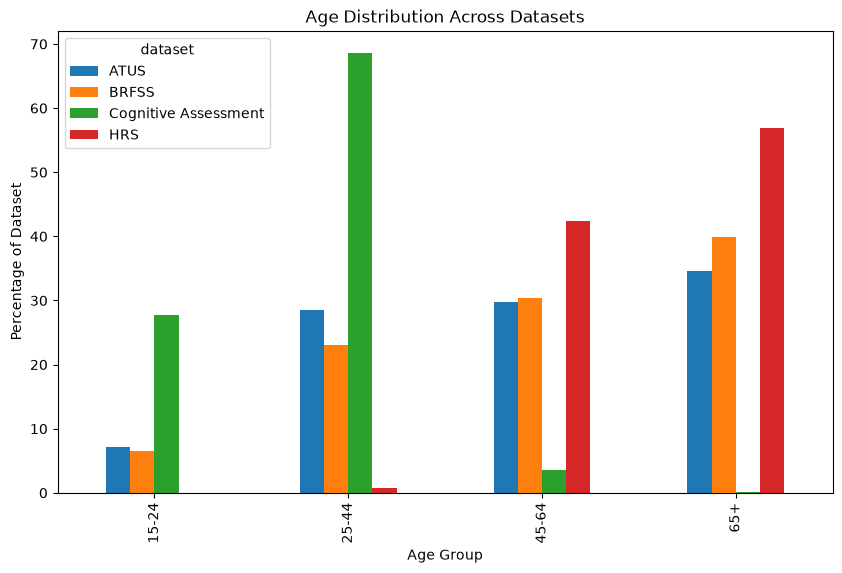

In [34]:
# combine age distributions from all four datasets
age_comparison = pd.concat([
    age_distribution_activities.assign(dataset="ATUS"),
    age_distribution_cognitive_data.assign(dataset="Cognitive Assessment"),
    age_distribution_mental_health.assign(dataset="BRFSS"),
    age_distribution_hrs.assign(dataset="HRS")], ignore_index=True)

#ChatGPT was used to generate the code for the age_comparison dataframe and for plotting age_comparison
age_order = ["15-24", "25-44", "45-64", "65+"]
age_comparison["age_group"] = pd.Categorical(age_comparison["age_group"], categories=age_order, ordered=True)

# plot age distribution
age_comparison.pivot(index="age_group", 
                     columns="dataset", 
                     values="percentage_of_population")\
                     .reindex(age_order)\
                     .plot.bar(figsize=(10,6), 
                               xlabel="Age Group", 
                               ylabel="Percentage of Dataset", 
                               title="Age Distribution Across Datasets")

### Initial Observation

It is clear that the Cognitive Assessment dataset has the largest proportion of younger respondents, particularly those between ages 15–24 and 25–44, while it contains very few respondents age 45 and older. In contrast, the HRS dataset is concentrated among older adults, with most respondents age 45 and above. The ATUS and BRFSS datasets have the most comparable age distributions, with respondents represented more evenly across the four age groups.

These differences are important because apparent differences in leisure behavior or health outcomes across datasets may partly reflect differences in the populations sampled. Therefore, later comparisons should focus on comparable age groups rather than treating all datasets as if they represented the same population.

### Passive Leisure Activities Across Age Groups in ATUS Survey

Next, we examine how passive leisure activity patterns differ across age groups in the ATUS data, comparing the average minutes across age groups allows us to identify preliminary patterns in how leisure behavior changes with age. 

Specifically, we will use `avg_grouped_activites`, to compare avg minutes spent watching tv(`avg_tv`), gaming (`avg_gaming`), and using a computer for leisure(`avg_computer`) per day.

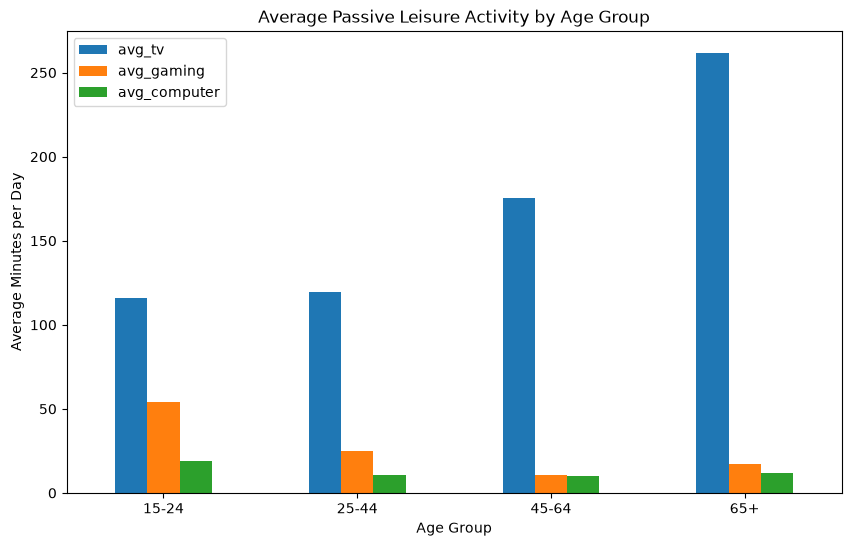

In [35]:
#ChatGPT was used to generate this plot
avg_grouped_activities.plot.bar(x="age_group",
                                y=["avg_tv", "avg_gaming", "avg_computer"],
                                figsize=(10,6),
                                xlabel="Age Group",
                                ylabel="Average Minutes per Day",
                                title="Average Passive Leisure Activity by Age Group")

plt.xticks(rotation=0)
plt.show()

### Passive Leisure Activities Across Age Groups in HRS Data

Next, we examine passive leisure behavior using the HRS dataset. Unlike ATUS, which records minutes spent on activities during a diary day, HRS records how frequently respondents participate in activities using categorical frequency codes.
- We display the percentage of respondents selecting each response code rather than interpreting the codes as minutes or continuous quantities.

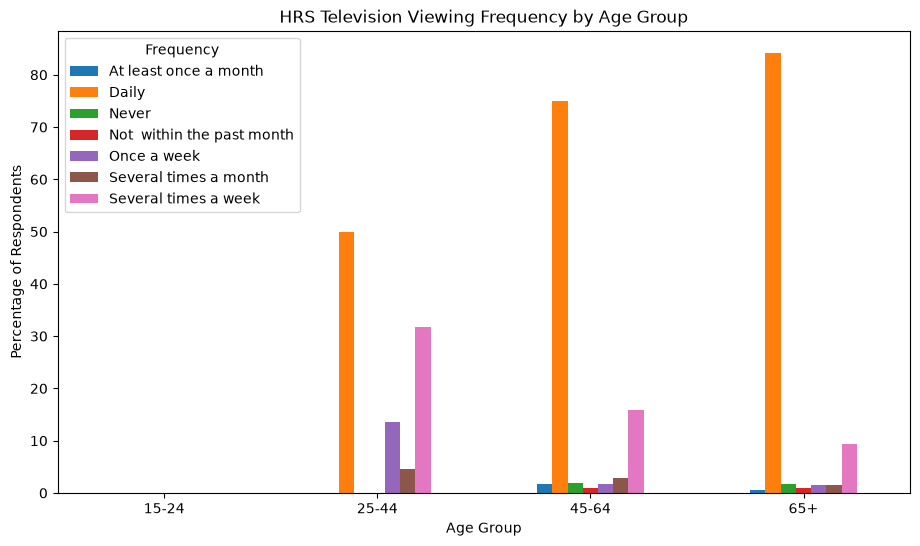

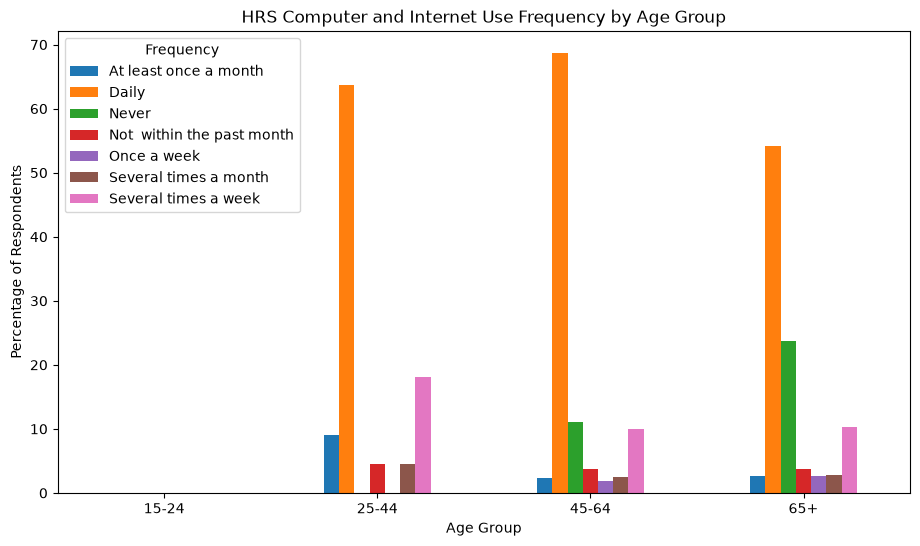

In [36]:
# Mapping of frequency codes to descriptive labels for HRS survey responses
frequency_map = {1: "Daily", 2: "Several times a week", 3: "Once a week", 4: "Several times a month", 5: "At least once a month", 6: "Not  within the past month", 7: "Never"}

# HRS television viewing frequency by age group
hrs_tv_by_age = duckdb.sql("SELECT age_group, watching_tv AS tv_frequency," \
                                   "COUNT(*) AS num_participants," \
                                   "ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY age_group), 2) AS percentage " \
                                   "FROM (SELECT " \
                                            "CASE WHEN age BETWEEN 15 AND 24 " \
                                                  "THEN '15-24' WHEN age BETWEEN 25 AND 44 " \
                                                  "THEN '25-44' WHEN age BETWEEN 45 AND 64 " \
                                                  "THEN '45-64' ELSE '65+' " \
                                            "END AS age_group, watching_tv " \
                                         "FROM hrs " \
                                         "WHERE age IS NOT NULL AND watching_tv IS NOT NULL) " \
                                   "GROUP BY age_group, watching_tv " \
                                   "ORDER BY age_group, watching_tv").df()

#map frequency codes to descriptive labels for easier interpretation
hrs_tv_by_age["tv_frequency"] = hrs_tv_by_age["tv_frequency"].map(frequency_map)

#plotting hrs_tv_plot
hrs_tv_plot = hrs_tv_by_age.pivot(index="age_group", 
                                  columns="tv_frequency", 
                                  values="percentage").fillna(0).reindex(["15-24", "25-44", "45-64", "65+"])

hrs_tv_plot.plot.bar(figsize=(11,6), 
                     xlabel="Age Group", 
                     ylabel="Percentage of Respondents", 
                     title="HRS Television Viewing Frequency by Age Group")
plt.xticks(rotation=0)
plt.legend(title="Frequency")
plt.show()

# HRS computer and internet use frequency by age group
hrs_computer_by_age = duckdb.sql("SELECT age_group, " \
                                   "computer_internet AS computer_frequency, " \
                                   "COUNT(*) AS num_participants, " \
                                   "ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY age_group), 2) AS percentage " \
                                   "FROM (SELECT " \
                                            "CASE WHEN age BETWEEN 15 AND 24 THEN '15-24' " \
                                                 "WHEN age BETWEEN 25 AND 44 THEN '25-44' " \
                                                 "WHEN age BETWEEN 45 AND 64 THEN '45-64' " \
                                                 "ELSE '65+' END AS age_group, " \
                                            "computer_internet AS computer_internet " \
                                         "FROM hrs " \
                                         "WHERE age IS NOT NULL AND computer_internet IS NOT NULL) " \
                                   "GROUP BY age_group, computer_internet " \
                                   "ORDER BY age_group, computer_internet").df()

#map frequency codes to descriptive labels for easier interpretation
hrs_computer_by_age["computer_frequency"] = hrs_computer_by_age["computer_frequency"].map(frequency_map)

#plotting hrs_computer_plot
hrs_computer_plot = hrs_computer_by_age.pivot(index="age_group", 
                                              columns="computer_frequency", 
                                              values="percentage").fillna(0).reindex(["15-24", "25-44", "45-64", "65+"])
hrs_computer_plot.plot.bar(figsize=(11,6),
                           xlabel="Age Group",
                           ylabel="Percentage of Respondents",
                           title="HRS Computer and Internet Use Frequency by Age Group")
plt.xticks(rotation = 0)
plt.legend(title = "Frequency")
plt.show()

### Active Leisure Activities Across Age Groups ATUS

Next, we examine how active leisure activity patterns differ across age groups, comparing the average minutes across age groups allows us to identify preliminary patterns in how leisure behavior changes with age.
- We compare reading, arts and crafts, and exercise to explore whether participation in these activities changes with age.

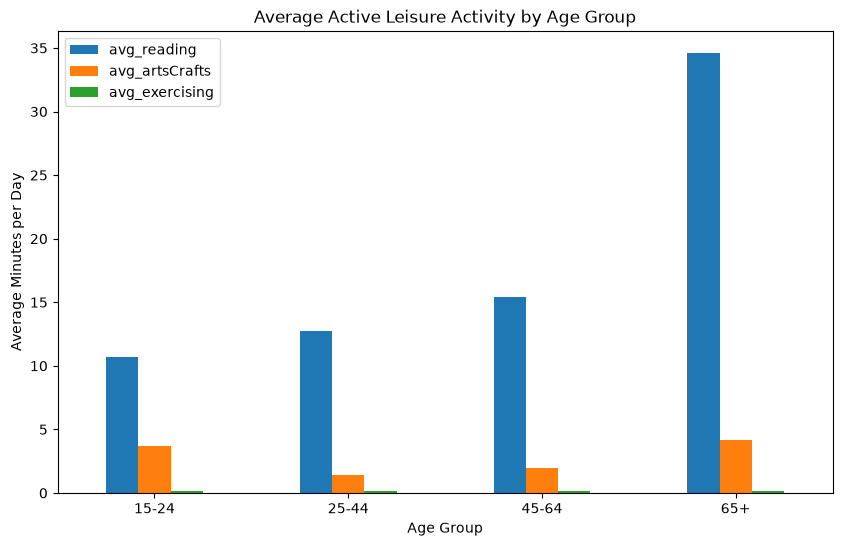

In [37]:
# ATUS dataset
avg_grouped_activities.plot.bar(x = "age_group",
                                y = ["avg_reading", "avg_artsCrafts", "avg_exercising"],
                                figsize = (10,6),
                                xlabel = "Age Group",
                                ylabel = "Average Minutes per Day",
                                title = "Average Active Leisure Activity by Age Group")

plt.xticks(rotation=0)
plt.show()

### Active Leisure Frequency Across Age Groups in HRS Data

Next, we examine active leisure activity frequency across age groups in the HRS dataset. Because HRS records using categorical frequency codes rather than minutes, we compare the percentage of respondents selecting each frequency code within each age group.
- Reading, exercise and walking

Index(['hhid', 'pn', 'education_training', 'reading', 'watching_tv',
       'word_games', 'card_games_chess', 'writing', 'computer_internet',
       'hobbies', 'exercising', 'walking', 'immediate_recall',
       'delayed_recall', 'trouble_falling_asleep', 'waking_at_night',
       'waking_too_early', 'feeling_rested', 'sitting_minutes',
       'sitting_hours', 'age', 'trouble_falling_asleep_clean',
       'waking_at_night_clean', 'waking_too_early_clean',
       'feeling_rested_clean', 'immediate_recall_clean',
       'delayed_recall_clean', 'reading_clean', 'walking_clean'],
      dtype='str')


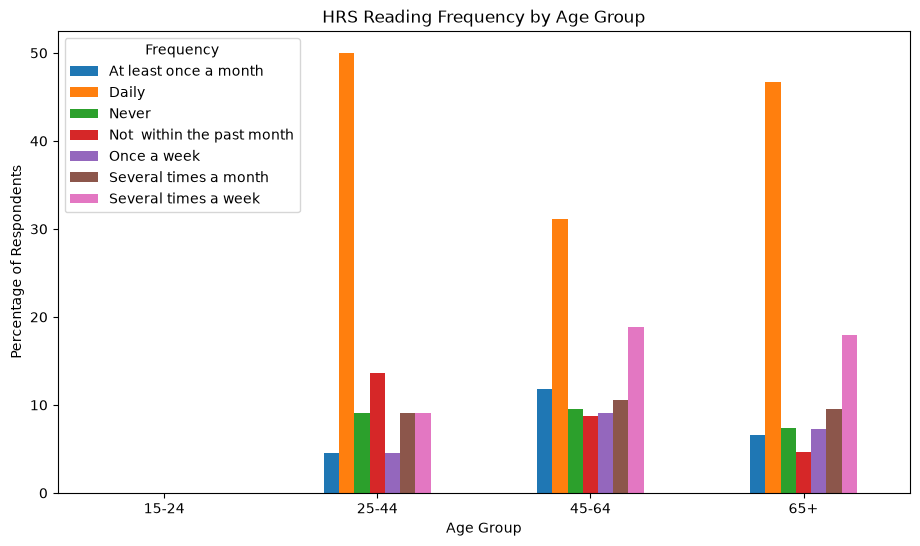

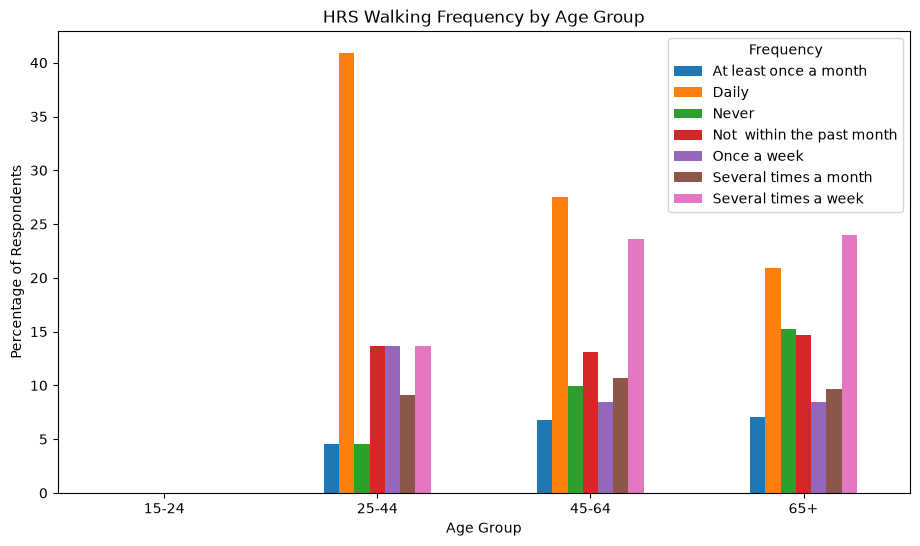

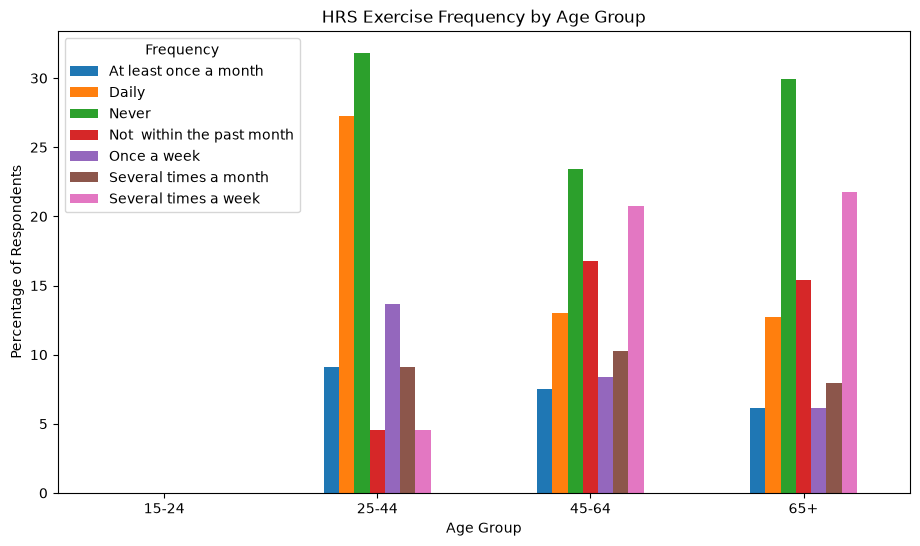

In [41]:
#reading frequency
hrs["reading_clean"] = hrs["reading"].where(hrs["reading"].between(1, 7), np.nan)
print(hrs.columns)
hrs_reading_by_age = duckdb.sql("""SELECT age_group, reading_frequency,
                                          COUNT(*) AS num_participants,
                                          ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY age_group), 2) AS percentage
                                    FROM(
                                        SELECT 
                                            CASE 
                                                WHEN age BETWEEN 15 AND 24 THEN '15-24' 
                                                WHEN age BETWEEN 25 AND 44 THEN '25-44' 
                                                WHEN age BETWEEN 45 AND 64 THEN '45-64' 
                                                ELSE '65+' 
                                            END AS age_group, reading_clean AS reading_frequency
                                        FROM hrs 
                                        WHERE age IS NOT NULL AND reading_clean IS NOT NULL
                                        )
                                    GROUP BY age_group, reading_frequency 
                                    ORDER BY age_group, reading_frequency""").df()

#map frequency codes to descriptive labels for easier interpretation
hrs_reading_by_age["reading_frequency"] = hrs_reading_by_age["reading_frequency"].map(frequency_map)

hrs_reading_plot = hrs_reading_by_age.pivot(index = "age_group", 
                                            columns = "reading_frequency", 
                                            values = "percentage").fillna(0).reindex(["15-24", "25-44", "45-64", "65+"])
hrs_reading_plot.plot.bar(figsize = (11,6),
                          xlabel = "Age Group",
                          ylabel = "Percentage of Respondents",
                          title = "HRS Reading Frequency by Age Group"
)

plt.xticks(rotation = 0)
plt.legend(title = "Frequency")
plt.show()

# walking frequency
hrs["walking_clean"] = hrs["walking"].where(hrs["walking"].between(1, 7), np.nan)

hrs_walking_by_age = duckdb.sql("""SELECT age_group, 
                                          walking_clean AS walking_frequency, 
                                          COUNT(*) AS num_participants, 
                                          ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY age_group), 2) AS percentage 
                                   FROM(
                                        SELECT 
                                            CASE 
                                                WHEN age BETWEEN 15 AND 24 THEN '15-24' 
                                                WHEN age BETWEEN 25 AND 44 THEN '25-44' 
                                                WHEN age BETWEEN 45 AND 64 THEN '45-64' 
                                                ELSE '65+' 
                                            END AS age_group, walking_clean 
                                        FROM hrs 
                                        WHERE age IS NOT NULL AND walking_clean IS NOT NULL)
                                    GROUP BY age_group, walking_clean 
                                    ORDER BY age_group, walking_clean""").df()

#map frequency codes to descriptive labels for easier interpretation
hrs_walking_by_age["walking_frequency"] = hrs_walking_by_age["walking_frequency"].map(frequency_map)

hrs_walking_plot = hrs_walking_by_age.pivot(index = "age_group", 
                                            columns = "walking_frequency", 
                                            values = "percentage").fillna(0).reindex(["15-24", "25-44", "45-64", "65+"])

hrs_walking_plot.plot.bar(figsize = (11,6),
                          xlabel = "Age Group",
                          ylabel = "Percentage of Respondents",
                          title = "HRS Walking Frequency by Age Group")

plt.xticks(rotation = 0)
plt.legend(title = "Frequency")
plt.show()

# exercise
hrs["exercise_clean"] = hrs["exercising"].where(hrs["exercising"].between(1, 7), np.nan)

hrs_exercise_by_age = duckdb.sql("""SELECT age_group, 
                                           exercise_clean  AS exercise_frequency, 
                                           COUNT(*) AS num_participants, 
                                           ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY age_group), 2) AS percentage 
                                    FROM (
                                        SELECT CASE 
                                                   WHEN age BETWEEN 15 AND 24 THEN '15-24' 
                                                   WHEN age BETWEEN 25 AND 44 THEN '25-44' 
                                                   WHEN age BETWEEN 45 AND 64 THEN '45-64' 
                                                   ELSE '65+' 
                                               END AS age_group, exercise_clean 
                                        FROM hrs 
                                        WHERE age IS NOT NULL AND exercise_clean IS NOT NULL
                                   ) 
                                   GROUP BY age_group, exercise_clean 
                                   ORDER BY age_group, exercise_clean""").df()
#map frequency codes to descriptive labels for easier interpretation
hrs_exercise_by_age["exercise_frequency"] = hrs_exercise_by_age["exercise_frequency"].map(frequency_map)

hrs_exercise_plot = hrs_exercise_by_age.pivot(index = "age_group", 
                                              columns = "exercise_frequency", 
                                              values = "percentage").fillna(0).reindex(["15-24", "25-44", "45-64", "65+"])

hrs_exercise_plot.plot.bar(figsize = (11,6),
                           xlabel = "Age Group",
                           ylabel = "Percentage of Respondents",
                           title = "HRS Exercise Frequency by Age Group")

plt.xticks(rotation=0)
plt.legend(title="Frequency")
plt.show()


# **Limitations:**

- **Age Disparities Among Datasets:** <br>
Our combined datasets primarily represent people aged 45+, so we might have to consider finding more data representative of younger people aged 15 - 24
- **Early Release Acknowledgement** <br>
One limitation is that the HRS 2024 data are an Early Release, meaning that some cleaning and processing have not yet been finalized. In particular, some web-based cognition variables, including immediate and delayed word recall, were still under review at the time of release. This should be acknowlaged somewhere in the project to prevent misguiding readers.
- **Missing Values**
Additionally, in the HRS 2024 Leave-Behind Questionnaire is administered to a selected subset respondents rather than the entire sample, so substantial missing data is expected when it is merged with the other Core files.
- **Diffrent Metric Comparison**
ATUS data uses number of minutes sitting or performing other leasurly activities while HRS uses frquency metric. This will make data harder to compare.

# **Questions for Reviewers:**

- How should we deal with HRS large quantity of NaN?
- How can we compare minutes and frequency measures?
- Do we have to choose a specific age range or can we use the current age spread established by ATUS even if our HRS data doesn't include younger age groups?

# **Part 2: Preregistration of analyses**
Preregister at least two analyses that you vow to present in your final report, no matter
the results (significant or not).
- Each preregistration statement should include 1) a hypothesis and 2) an analysis
that will be run to support that hypothesis.
-   Do not perform these analyses, check they are significant, and then “preregister” them.
That defeats the purpose. You can learn a lot from associations that are not
statistically significant!
-   Keep in mind that for your final report, you must provide at least one model
showing patterns or relationships between variables that addresses your research
question.
- Include a "Questions for reviewers" section at the end of your submission, listing
specific questions for your project mentor to answer in giving you feedback on this
phase.